In [55]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [56]:
from src.models import normal_equation

In [57]:
import numpy as np 

np.random.seed(42)
m = 100

X = 2 * np.random.rand(m, 1)
y = 4 + 3 * X + np.random.randn(m, 1)

X_b = np.c_[np.ones((m, 1)), X]

In [58]:
theta_normal = normal_equation(X, y)
theta_normal

array([[4.21509616],
       [2.77011339]])

In [59]:
def learning_schedule(t, t0=5, t1=50):
    return t0 / (t + t1)

In [60]:
def stochastic_GD(
        X_b, y, n_epochs=50, t0=5, t1=50, random_state=42      
):
    np.random.seed(random_state)
    m = len(X_b)
    theta = np.random.randn(2, 1)
    cost_history = []
    etas = []
    for epoch in range(n_epochs):
        for iteration in range(m):
            i = np.random.randint(m)

            xi = X_b[i : i + 1]
            yi = y[i : i + 1]

            gradient = 2 * xi.T @ (xi @ theta - yi)
            eta = learning_schedule(epoch * m + iteration)
            theta = theta - eta * gradient

        cost = np.mean((X_b @ theta - y) ** 2)
        cost_history.append(cost)
        etas.append(eta)
        
    return theta, cost_history, etas
        

In [61]:
theta_sgd, cost_sgd, etas = stochastic_GD(X_b, y)

print("Theta Normal: ")
print(theta_normal)

print("\nTheta SGD: ")
print(theta_sgd)

print("\nMatches Normal Equation:")
print(np.allclose(theta_normal, theta_sgd))

Theta Normal: 
[[4.21509616]
 [2.77011339]]

Theta SGD: 
[[4.21076011]
 [2.74856079]]

Matches Normal Equation:
False


### Why SGD doesn't exactly match the Normal Equation

The Normal Equation solves for the optimal parameters directly: it inverts `XᵀX` and lands on the exact minimizer in one shot. SGD approaches the same optimum through many small, noisy updates, so it never lands on it exactly. There are two reasons:

1. **Each step uses one random row.** The single-instance gradient is only a rough estimate of the true gradient, so θ jitters around the minimum instead of marching straight to it. Different random draws give different directions, and the final θ depends on which rows were visited last.

2. **The learning rate never reaches zero.** At the final step of the book's schedule, `η = 5 / (4999 + 50) ≈ 0.001`. That's small, but not zero — so θ is still moving when the loop ends. The cost curve reflects this: it settles in the 0.806–0.820 band rather than flattening at the optimum (0.8066).

The plot below shows the decay: `η` starts at 0.1 and shrinks geometrically, which is why the early epochs move fast and the late epochs barely move at all.

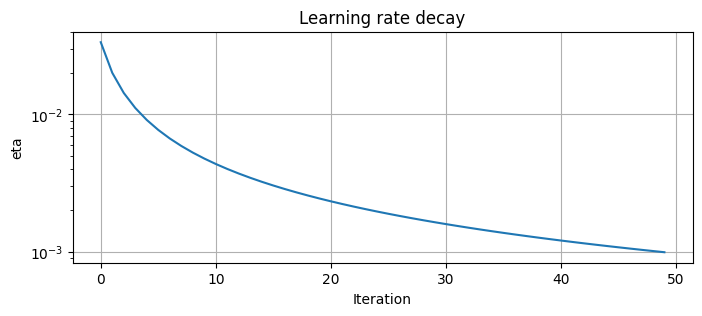

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 3))
plt.plot(etas)
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("eta")
plt.title("Learning rate decay")
plt.grid(True)
plt.show()

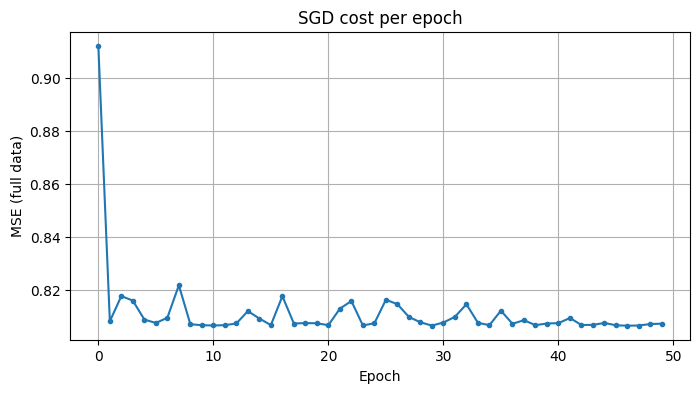

In [63]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.plot(cost_sgd, marker='o', markersize=3)
plt.xlabel("Epoch")
plt.ylabel("MSE (full data)")
plt.title('SGD cost per epoch')
plt.grid(True)
plt.show()

In [64]:
print("First 5 costs: ", cost_sgd[:5])
print("Last 5 costs: ", cost_sgd[-5:])

First 5 costs:  [np.float64(0.9121974467141009), np.float64(0.8082584882744887), np.float64(0.8177757962205604), np.float64(0.8160544619916275), np.float64(0.8089180886756796)]
Last 5 costs:  [np.float64(0.8067547726896425), np.float64(0.8065881789920034), np.float64(0.806669950790068), np.float64(0.8072281763806772), np.float64(0.8073526785229235)]


### Why is there noise in SGD Cost?

Unlike **Batch Gradient Descent**, SGD updates the parameters using one randomly selected training example at a time. Each example produces a different gradient, causing the parameters to fluctuate around the optimum rather than move smoothly toward it.

This randomness creates noise in the cost curve. The cost drops sharply during the initial epochs, then fluctuates around approximately 0.802 as the learning rate decreases. The smaller learning rate reduces the magnitude of these fluctuations, allowing SGD to settle near the optimum.

### Learning-Rate Experiment — Prediction, Constant eta = 0.1

With a constant learning rate eta = 0.1, SGD should be noisier than with the decaying schedule

Early on, the schedule starts at `eta = t0 / (0 + t1) = 5 / 50 = 0.1`, so the first steps are the same size. But the schedule then shrinks **eta**, so later updates become smaller and the cost can settle.

With constant **eta = 0.1**, the step size never shrinks, so the parameters keep bouncing around the minimum.

I expect the constant version to end up noisier and likely farther from `theta_normal`, or at least with a higher and more variable last-10-epoch cost.

In [65]:
def stochastic_gradient_descent_constant(
    X_b, y, n_epochs=50, eta=0.1, random_state=42
):
    np.random.seed(random_state)
    m = len(X_b)
    theta = np.random.randn(2, 1)
    cost_history = []

    for epoch in range(n_epochs):
        for iteration in range(m):
            i = np.random.randint(m)

            xi = X_b[i:i+1]   # (1, 2)
            yi = y[i:i+1]     # (1, 1)

            gradients = 2 * xi.T @ (xi @ theta - yi)
            theta = theta - eta * gradients

        cost = (1 / m) * np.sum((X_b @ theta - y) ** 2)
        cost_history.append(cost)

    return theta, cost_history

In [66]:
theta_const, cost_const = stochastic_gradient_descent_constant(
    X_b, y, n_epochs=50, eta=0.1
)

print("theta_const       :", theta_const.ravel())
print("theta_sgd schedule:", theta_sgd.ravel())
print("theta_normal      :", theta_normal.ravel())

print("\nLast 10 costs (schedule):", np.round(cost_sgd[-10:], 4))
print("Last 10 costs (constant):", np.round(cost_const[-10:], 4))

theta_const       : [3.7625155 2.5892927]
theta_sgd schedule: [4.21076011 2.74856079]
theta_normal      : [4.21509616 2.77011339]

Last 10 costs (schedule): [0.8076 0.8095 0.8069 0.8069 0.8076 0.8068 0.8066 0.8067 0.8072 0.8074]
Last 10 costs (constant): [1.2285 2.4737 0.9625 0.8289 0.8739 1.0314 0.8821 0.8493 0.8315 1.2057]


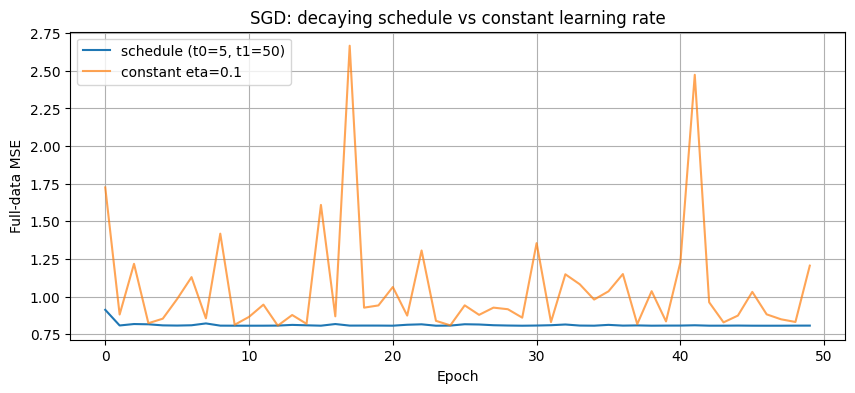

In [67]:
plt.figure(figsize=(10, 4))
plt.plot(cost_sgd, label="schedule (t0=5, t1=50)")
plt.plot(cost_const, label="constant eta=0.1", alpha=0.7)
plt.xlabel("Epoch")    
plt.ylabel("Full-data MSE")
plt.title("SGD: decaying schedule vs constant learning rate")
plt.legend()
plt.grid(True)
plt.show()    

In [68]:
def minibatch_gradient_descent(
        X_b, y, batch_size, n_epochs=50, t0=5, t1=50, random_state=42
):
    np.random.seed(random_state)
    m = len(X_b)
    theta = np.random.randn(2, 1)
    cost_history = [] 
    t = 0

    for epoch in range(n_epochs):
        indices = np.random.permutation(m)
        X_shuffled = X_b[indices]
        y_shuffled = y[indices]

        for i in range(0, m, batch_size):
            Xb = X_shuffled[i:i+batch_size]
            yb = y_shuffled[i:i+batch_size]

            gradients = (2 / len(Xb)) * Xb.T @ (Xb @ theta - yb)
            eta = learning_schedule(t, t0, t1)
            theta = theta - eta * gradients
            t+=1

        cost = np.mean((X_b @ theta - y) ** 2)
        cost_history.append(cost)

    return theta, cost_history

In [69]:
batch_sizes = [1, 10, 20, 100]
results = {}

for bs in batch_sizes:
    theta_mb, cost_mb = minibatch_gradient_descent(
        X_b, y, batch_size=bs, n_epochs=50, t0=5, t1=50
    )
    results[bs] = (theta_mb, cost_mb)
    print(f"batch size={bs:3d}, theta = {theta_mb.ravel()}")

print("\ntheta_normal = ", theta_normal.ravel())

batch size=  1, theta = [4.21401215 2.7688003 ]
batch size= 10, theta = [4.2031432  2.77808302]
batch size= 20, theta = [4.18308151 2.79583749]
batch size=100, theta = [4.02033725 2.9420747 ]

theta_normal =  [4.21509616 2.77011339]


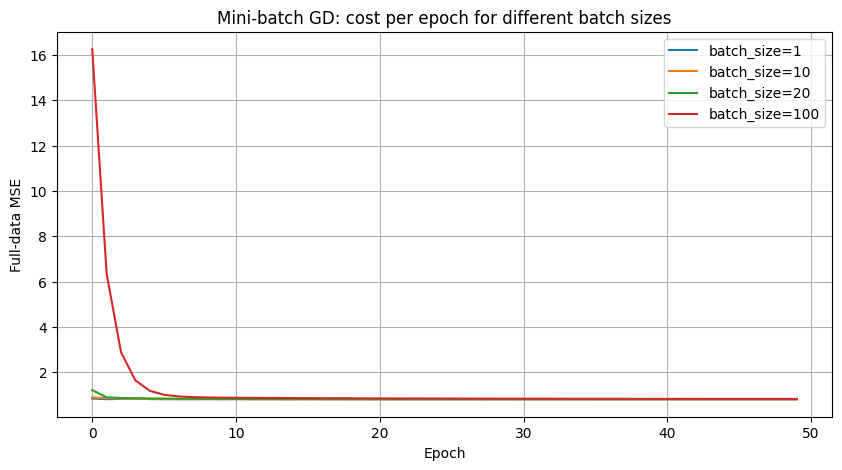

In [70]:
plt.figure(figsize=(10, 5))
for bs in batch_sizes:
    plt.plot(results[bs][1], label=f"batch_size={bs}")
plt.xlabel("Epoch")
plt.ylabel("Full-data MSE")
plt.title("Mini-batch GD: cost per epoch for different batch sizes")
plt.legend()
plt.grid(True)
plt.show()

In [71]:
from src.gradient_descent import batch_gradient_descent

theta_init = np.random.randn(2, 1)
theta_batch, cost_batch = batch_gradient_descent(X_b, y, eta=0.1, n_iterations=1000, theta_init=theta_init)

theta_mb100, cost_mb100 = minibatch_gradient_descent(
    X_b, y, batch_size=100, n_epochs=1000, t0=5, t1=50
)
print("Batch GD theta      :", theta_batch.ravel())
print("Mini-batch bs=100   :", theta_mb100.ravel())
print("theta_normal        :", theta_normal.ravel())

Batch GD theta      : [4.21509616 2.77011339]
Mini-batch bs=100   : [4.2115696  2.77322715]
theta_normal        : [4.21509616 2.77011339]


In [72]:
from sklearn.linear_model import SGDRegressor

sgd_reg_ns = SGDRegressor(
    max_iter=1000,
    tol=1e-5,
    penalty=None,
    eta0=0.01,
    n_iter_no_change=100,
    random_state=42,
)
sgd_reg_ns.fit(X, y.ravel())

theta_sklearn_ns = np.array([sgd_reg_ns.intercept_[0], sgd_reg_ns.coef_[0]])
print("SGDRegressor:", theta_sklearn_ns)
print("theta_normal:", theta_normal.ravel())

SGDRegressor: [4.21278812 2.77270267]
theta_normal: [4.21509616 2.77011339]


## Comparison: how to train a linear regression model

| | Normal Equation | SVD (`LinearRegression`) | Batch GD | Stochastic GD | Mini-batch GD |
|---|---|---|---|---|---|
| Fast with large m (many instances)? | No — O(mn²) to build XᵀX, plus O(n³) inverse | No — O(mn²) decomposition | No — each step is O(mn), so slow per step | Yes — each step is O(n), one row | Yes — each step is O(Bn), B small |
| Fast with large n (many features)? | No — O(n³) inverse kills it | No — O(n³)-ish | OK per step (O(mn)) but conditioning worsens | OK per step (O(n)) but noisy | OK per step (O(Bn)) |
| Out-of-core support? | No | No | Yes (chunk the gradient) | Yes (row by row) | Yes (batch by batch) |
| Number of hyperparameters | 0 | 0 | 1 (learning rate eta) | 3 (schedule t0, t1, n_epochs) | 4 (schedule t0, t1, n_epochs, batch_size B) |
| Needs feature scaling? | No | No | Yes | Yes (even more sensitive) | Yes |
| Scikit-Learn class | `LinearRegression` (with `solver='normal'` internal path) | `LinearRegression` (default `solver='svd'`) | none built-in | `SGDRegressor` | `SGDRegressor` (or `SGDClassifier`) with a batch loop you write yourself |
| Path to the minimum | one shot | one shot | smooth | very noisy, bounces around | noisy but smoother than SGD |
| Number I measured in my notebooks | one shot (closed form) | one shot (closed form) | 365 iters (tol 1e-6) | ~50 epochs × 100 steps = 5000 updates | e.g. bs=20, 50 epochs → 250 updates |

### When I'd pick each

- 10,000 rows, 5 features → Normal Equation or SVD (LinearRegression).
Because it's tiny: m and n are both small, so the closed-form solution is basically instant, has zero hyperparameters, and needs no scaling. GD would work too, but there's no reason to pay for tuning.

- 10,000,000 rows, 20 features → SGD or Mini-batch GD.
Because m is huge. Normal Equation / SVD would need O(mn²) + O(n³), which is slow and memory-hungry. SGD/mini-batch give cheap O(n) or O(Bn) steps and can stream the data. Mini-batch is usually smoother and GPU-friendly; SGD is simplest if you only need a rough fit.

- 100,000 features → SGD or Mini-batch GD (and if you actually have the memory, SVD is still better numerically than Normal Equation).
Because n is huge: the O(n³) inverse/decomposition is the real wall. GD variants only pay O(n) per step. But you'd better scale features and probably use regularization.

- Data that doesn't fit in RAM → SGD or Mini-batch GD (out-of-core).
Because they are the only methods here that can update from one row or one small batch at a time. Normal Equation and SVD need the whole design matrix; Batch GD can technically be chunked, but it's still O(m) per step, so on out-of-core data SGD/mini-batch is the practical choice.

